In [214]:
import os
from pathlib import Path
import src.config as config
from src.audio import load_audio, rms_db
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [1]:
# _t = torch.from_numpy(np.load("precomputed/train_v3/00454.npz", mmap_mode="r")["mel"]).unsqueeze(0).unsqueeze(0)
# librosa.display.specshow(data=spec_augment(_t).squeeze(0).squeeze(0).numpy(), sr=SR, hop_length=HOP_LENGTH)
# librosa.display.specshow(
#     librosa.power_to_db(librosa.feature.melspectrogram(y=load_audio("data/messy_mashup/mashups/song0002.wav")), ref=np.max),
#     sr=SR)
# librosa.display.specshow(data=spec_augment(_t).squeeze(0).squeeze(0).cpu().numpy(), cmap="magma")

### Basic exploration

First off, how many files are there in the datasets?

In [131]:
stems = [f for f in Path(config.STEMS_DIR).rglob("*.wav")]
genres = sorted([p for p in Path(config.STEMS_DIR).iterdir()])
noises = sorted([p for p in Path(config.NOISE_DIR).iterdir() if p.is_file()])
test_paths = sorted([f for f in Path(config.TEST_DIR).iterdir() if f.is_file()])

print(f"Stems: {len(stems)}")
print(f"Genres: {len(genres)} ({[p.name for p in genres]})")
print(f"ESC-50: {len(noises)}")
print(f"Test: {len(test_paths)}")

Stems: 4000
Genres: 10 (['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'])
ESC-50: 2000
Test: 3020


Taking a quick look at the audio files themselves:

In [132]:
print(f"Stem: SR={librosa.get_samplerate(stems[0])}, channels={librosa.load(stems[0], mono=False)[0].ndim}")
print(f"Noise: SR={librosa.get_samplerate(noises[0])}, channels={librosa.load(noises[0], mono=False)[0].ndim}")
print(f"Test: SR={librosa.get_samplerate(test_paths[0])}, channels={librosa.load(test_paths[0], mono=False)[0].ndim}")

Stem: SR=44100, channels=2
Noise: SR=44100, channels=1
Test: SR=22050, channels=1


So:

- The GTZAN stems are sampled at 44.1 kHz in stereo
- The noises are sampled at 44.1 kHz in mono 
- The test mashups are sampled at 22.05 kHz in mono

So the stems need to be loaded as mono (by averaging across the channels), which `librosa` does by default when loading `.wav`s. Also, I'll resample all the audio files to 22050 Hz across the board, just to simplify things - the additional fidelity doesn't really matter for a task like this, and it'll save on disk space and training time.

Breaking down genres further:

In [218]:
songs_by_genre = dict()
for g in genres:
    songs_by_genre[g.name] = sorted([str(d) for d in (Path(config.STEMS_DIR)/g.name).iterdir()])
songs_by_genre

{'blues': ['data/messy_mashup/genres_stems/blues/blues.00000',
  'data/messy_mashup/genres_stems/blues/blues.00001',
  'data/messy_mashup/genres_stems/blues/blues.00002',
  'data/messy_mashup/genres_stems/blues/blues.00003',
  'data/messy_mashup/genres_stems/blues/blues.00004',
  'data/messy_mashup/genres_stems/blues/blues.00005',
  'data/messy_mashup/genres_stems/blues/blues.00006',
  'data/messy_mashup/genres_stems/blues/blues.00007',
  'data/messy_mashup/genres_stems/blues/blues.00008',
  'data/messy_mashup/genres_stems/blues/blues.00009',
  'data/messy_mashup/genres_stems/blues/blues.00010',
  'data/messy_mashup/genres_stems/blues/blues.00011',
  'data/messy_mashup/genres_stems/blues/blues.00012',
  'data/messy_mashup/genres_stems/blues/blues.00013',
  'data/messy_mashup/genres_stems/blues/blues.00014',
  'data/messy_mashup/genres_stems/blues/blues.00015',
  'data/messy_mashup/genres_stems/blues/blues.00016',
  'data/messy_mashup/genres_stems/blues/blues.00017',
  'data/messy_mashu

In [133]:
for g in genres:
    dirs = sorted([p for p in g.iterdir() if p.is_dir()])
    print(f"{g.name}: {len(dirs)} songs")
    for d in dirs:
        files = [f for f in d.iterdir() if f.is_file()]
        if len(files) != 4:
            print(f"WARNING: {d} doesn't contain all 4 stems.")
        for f in files:
            if os.stat(f).st_size < 4096: # Should be larger than 4 KB
                print(f"WARNING: {f} is likely corrupt.")
            if librosa.get_samplerate(f) != 44100:
                print(f"WARNING: {f} has a mismatched sample rate.")

blues: 100 songs
classical: 100 songs
country: 100 songs
disco: 100 songs
hiphop: 100 songs
jazz: 100 songs
metal: 100 songs
pop: 100 songs
reggae: 100 songs
rock: 100 songs


So the song stems are class-balanced, and there are no missing stems. What about the noises? ESC-50 includes a `.csv` that contains metadata about all the noises. Let's load that into a dataframe.

In [116]:
noise_df = pd.read_csv("data/messy_mashup/ESC-50-master/meta/esc50.csv")
noise_df["category"].value_counts().sort_index(), noise_df["category"].nunique()

(category
 airplane            40
 breathing           40
 brushing_teeth      40
 can_opening         40
 car_horn            40
 cat                 40
 chainsaw            40
 chirping_birds      40
 church_bells        40
 clapping            40
 clock_alarm         40
 clock_tick          40
 coughing            40
 cow                 40
 crackling_fire      40
 crickets            40
 crow                40
 crying_baby         40
 dog                 40
 door_wood_creaks    40
 door_wood_knock     40
 drinking_sipping    40
 engine              40
 fireworks           40
 footsteps           40
 frog                40
 glass_breaking      40
 hand_saw            40
 helicopter          40
 hen                 40
 insects             40
 keyboard_typing     40
 laughing            40
 mouse_click         40
 pig                 40
 pouring_water       40
 rain                40
 rooster             40
 sea_waves           40
 sheep               40
 siren               40
 sneez

So the noises are also class-balanced, with 40 samples each for 50 unique classes.

### Test samples

In [181]:
test_ids = [f.name.split(".")[0] for f in test_paths]
df = pd.DataFrame(zip(test_ids, test_paths), columns=["id", "path"])
df["duration"] = df["path"].apply(lambda p: librosa.get_duration(path=p, sr=config.SR))
df[["duration"]].describe()

,duration
count,3020.000000
mean,28.653240
std,3.773619
min,6.060408
25%,29.628662
50%,29.953741
75%,30.013333
max,30.579229


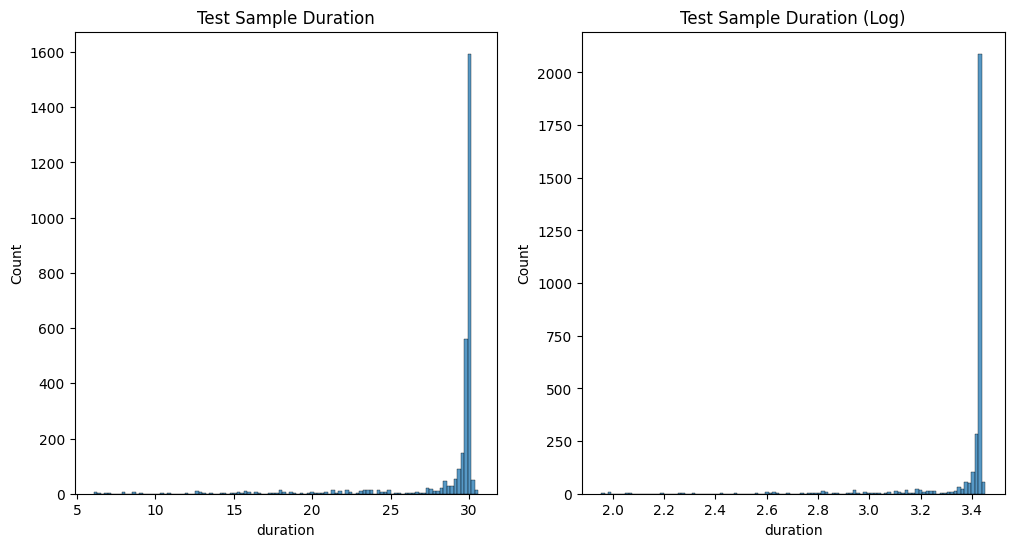

In [200]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=df["duration"], ax=ax[0])
sns.histplot(data=np.log1p(df["duration"]), ax=ax[1])
ax[0].set_title("Test Sample Duration")
ax[1].set_title("Test Sample Duration (Log)")
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.histplot(data=df["duration"], ax=ax[0])
sns.histplot(data=np.log1p(df["duration"]), ax=ax[1])
ax[0].set_title("Test Sample Duration")
ax[1].set_title("Test Sample Duration (Log)")
plt.show()

In [209]:
stem_durations = [librosa.get_duration(path=f, sr=config.SR) for f in stems]
pd.Series(stem_durations).describe()

count    4000.000000
mean       30.024047
std         0.080883
min        29.931973
25%        30.000181
50%        30.013333
75%        30.013333
max        30.648889
dtype: float64

In [213]:
noise_durations = [librosa.get_duration(path=f, sr=config.SR) for f in noises]
pd.Series(noise_durations).describe()

count    2000.0
mean        5.0
std         0.0
min         5.0
25%         5.0
50%         5.0
75%         5.0
max         5.0
dtype: float64

### Features

In [220]:
def get_features(path, sr=config.SR, n_mels=config.N_MELS, n_fft=config.N_FFT, hop_length=config.HOP_LENGTH):
    y = load_audio(path, sr=sr)
    duration = len(y)/sr
    rmsdb = rms_db(y)
    zcr = librosa.feature.zero_crossing_rate(y=y, hop_length=hop_length)[0].mean()
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)[0].mean()
    flatness = librosa.feature.spectral_flatness(y=y, n_fft=n_fft, hop_length=hop_length)[0].mean()
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, roll_percent=0.85)[0].mean()
    return dict(duration=duration, rms_db=rmsdb, zcr=zcr, centroid=centroid, flatness=flatness, rolloff=rolloff)

In [221]:
features = [get_features(f) for f in test_paths]

In [224]:
ft_df = pd.DataFrame.from_dict(features)
ft_df.describe()

,duration,rms_db,zcr,centroid,flatness,rolloff
count,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000,3020.000000
mean,28.653240,-17.146095,0.106069,2288.680010,0.022167,4757.699028
std,3.773619,1.555617,0.038342,586.605961,0.016364,1238.528472
min,6.060408,-23.330507,0.007506,433.976796,0.000150,712.460915
25%,29.628662,-18.071653,0.079992,1901.672551,0.010532,3934.649275
50%,29.953741,-17.152581,0.103493,2272.557383,0.018120,4776.839060
75%,30.013333,-16.193314,0.128773,2663.163209,0.029710,5574.531133
max,30.579229,-7.595422,0.304043,4472.006211,0.127426,8248.715628


### Comparing synthetic distribution to test